## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Cody Chhea 

**Date:** 10/12/2026

<Axes: xlabel='x1', ylabel='x2'>

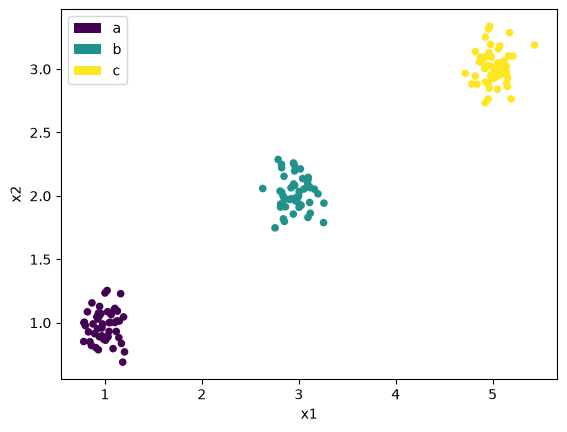

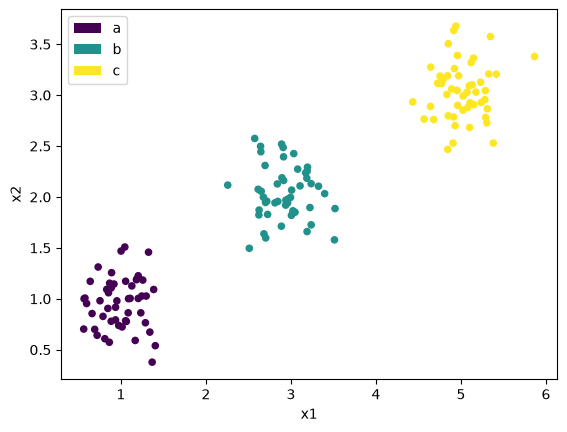

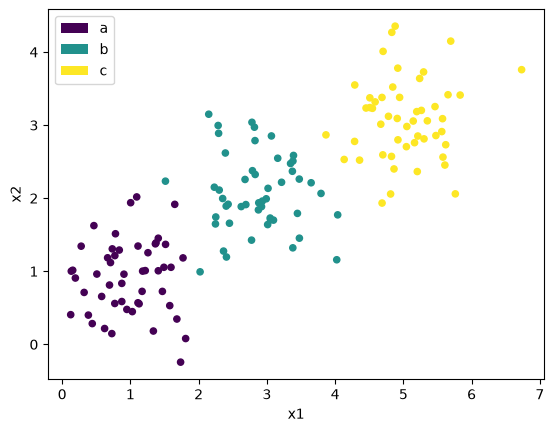

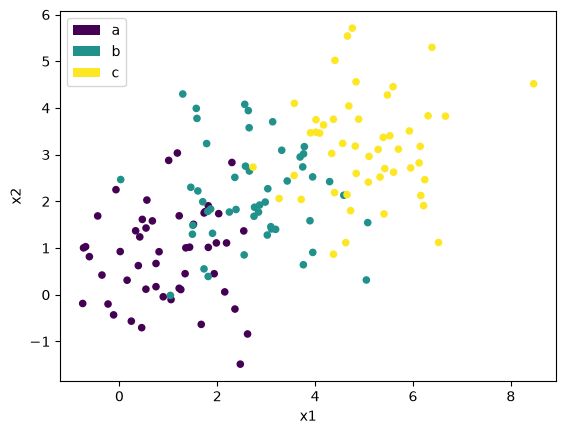

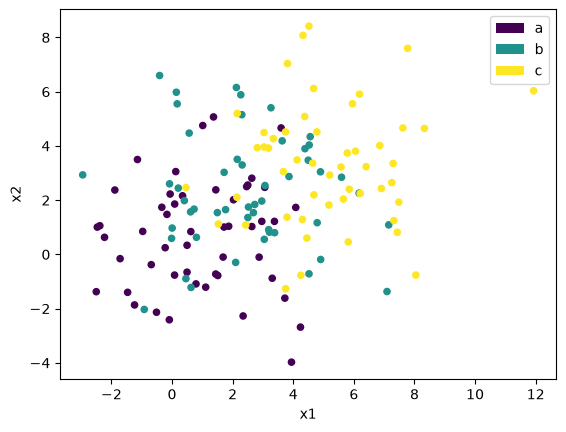

In [44]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

df0_125.plot.scatter(x='x1',y='x2',c='group')
df0_25.plot.scatter(x='x1',y='x2',c='group')
df0_5.plot.scatter(x='x1',y='x2',c='group')
df1_0.plot.scatter(x='x1',y='x2',c='group')
df2_0.plot.scatter(x='x1',y='x2',c='group')



As the noise of the graphs increased, the points within each group became more scattered rather than clustered. The three groups drifted enough to begin mixing and merging with one another, transitioning from distinct clusters into a single, unified group

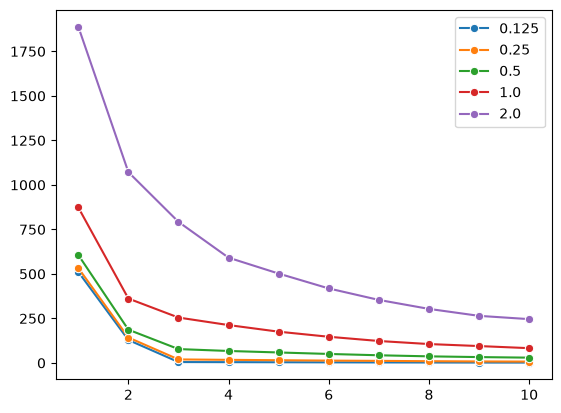

In [8]:
import seaborn as sns
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
ks = np.arange(1, 11)
X1 = df0_125[['x1', 'x2']].values
X2 = df0_25[['x1', 'x2']].values
X3 = df0_5[['x1', 'x2']].values
X4 = df1_0[['x1', 'x2']].values
X5 = df2_0[['x1', 'x2']].values
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X1).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label="0.125", marker = "o")
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X2).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label="0.25", marker = "o")

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X3).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label="0.5", marker = "o")

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X4).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label="1.0", marker = "o")

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X5).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label="2.0", marker = "o")
plt.legend()
plt.show()





In [48]:
model = KMeans(
    n_clusters=3, n_init=10, max_iter=300, random_state=0
)
model.fit(X1)
sse_value = model.inertia_
print(sse_value)


model.fit(X2)
sse_value = model.inertia_
print(sse_value)


model.fit(X5)
sse_value = model.inertia_
print(sse_value)




4.913218522689869
19.652874090759475
792.2717571884425


3) As noise increases, the SSE values increase drastically. For example at k = 3, the SSE value of the 0.125 and .25 graphs were 4.9 and 19.6 respectively. However, the value of the 2.0 graph was 792, a drastic difference. However, noise affects our ability to select a k. At low noise, there is a sharp elbow, which makes it easy to have a definitive k value. However, at high noise, it makes it harder as each extra cluster after k = 2 cuts SSE by a similar amount. 

4) As k rises, SSE values drop. More clusters means each point is closer to a center, so SSE drops.The thing we specifically look at to determine a good k value is the size of each drop changes. Once k matches the real number of groups there should be, adding more k values doesn't change SSE values as drastically. Each cluster already fits a group, so adding more clusters will only split groups that belong together, which doesn't lower SSE much. Because of this characteristic of SSE not dropping by the same amount each time, an elbow sort of forms, which also makes it a good rule of thumb that the elbow tells us where the switch from steep to flat is.

In [52]:
#Part 2
df = pd.read_csv(r'C:\Users\cchhe\OneDrive\Desktop\DS3001\A04-k-clustering\SIPRI Military Expenditure Database.csv')
df.head()

df_cleaned = df[df['Year'] == 2020]
df_cleaned = df_cleaned.dropna()
df_cleaned.describe()
df_cleaned['Spending (2020 USD)'].describe()




count       148.000000
mean      13153.747670
std       68005.236120
min           8.622460
25%         204.877177
50%         959.535443
75%        5289.998320
max      778397.200000
Name: Spending (2020 USD), dtype: float64

<Axes: xlabel='Spending (2020 USD)'>

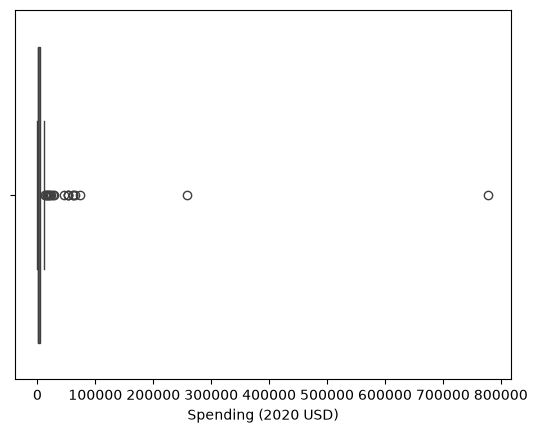

In [38]:
sns.boxplot(x=df_cleaned['Spending (2020 USD)'])

1. It looks like there are clear outliers that can be removed. However, because of the nature of the next question which talks about the location of US (an outlier), I am going to not remove the outlier. Otherwise, no furthur cleaning is needed as values are all numeric and there are no duplicates.

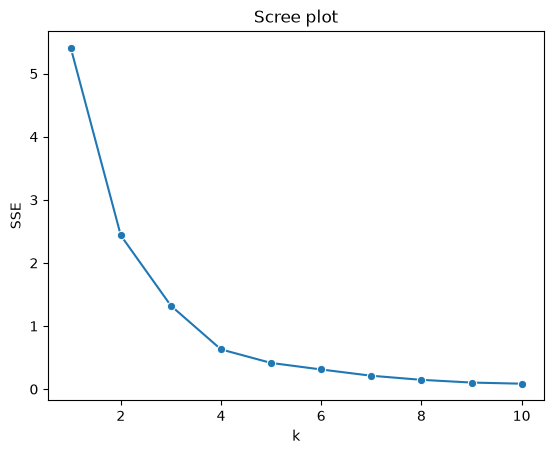

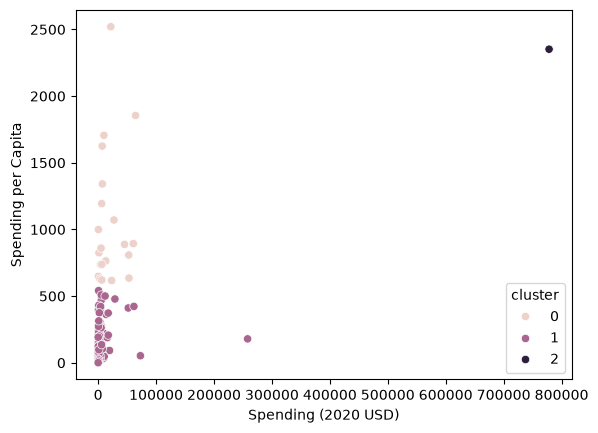

        Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      21.0   19975.991473  21749.736747     405.790494   
1                     126.0    5943.346303  24858.961064       8.622460   
2                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          4980.428135    7269.880030   27300.894701   64558.400000   
1           162.761743     580.758315    3225.333414  257973.429834   
2        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita                                        \
                      count         mean         std 

In [45]:
from sklearn.cluster import KMeans

#max-min normalizing spending and spending per capita
features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = df_cleaned.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

ks = range(1, 11)
SSE = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
sns.lineplot(x=ks, y=SSE, marker='o') 
plt.xlabel('k')
plt.ylabel('SSE') 
plt.title('Scree plot')
plt.show()

k = 3
df_cleaned['cluster'] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)

sns.scatterplot(data=df_cleaned, x='Spending (2020 USD)', y='Spending per Capita', hue='cluster')
plt.show()
print(df_cleaned.groupby('cluster')[features].describe())

print(df_cleaned[df_cleaned['Country'] == 'United States of America'][['Country', 'cluster']])




                       Country  Spending (2020 USD)
1052                     China        257973.429834
5540  United States of America        778397.200000


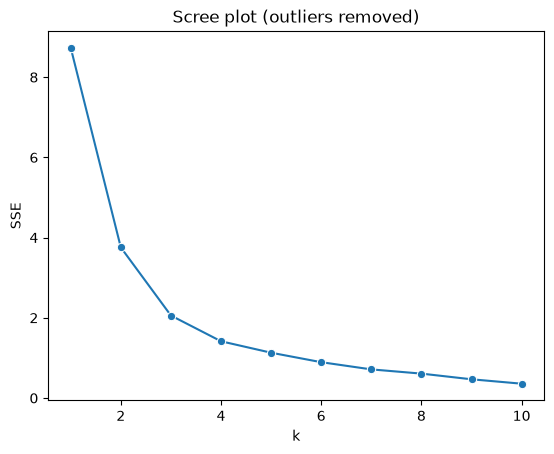

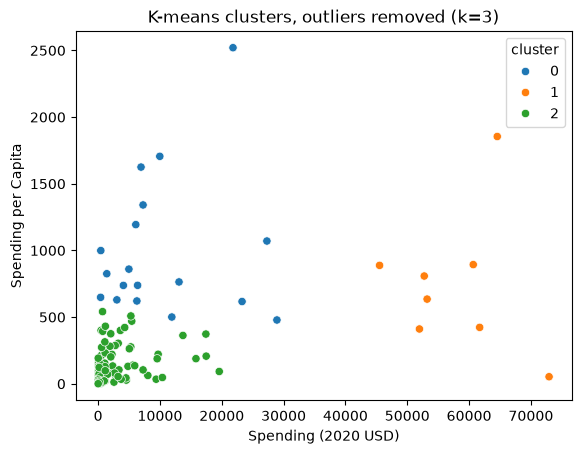

cluster                               0             1             2
Spending (2020 USD) count     18.000000      8.000000    120.000000
                    mean   10201.409102  57916.988702   2195.189599
                    std     9110.123194   8697.634598   3846.143773
                    min      405.790494  45523.984708      8.622460
                    25%     4310.763024  52553.006382    152.121545
                    50%     6665.356103  56943.013942    501.546784
                    75%    12795.207557  62424.002877   2589.336589
                    max    28921.342756  72937.064048  19591.209004
Spending per Capita count     18.000000      8.000000    120.000000
                    mean     993.044082    745.741724    111.096280
                    std      524.393190    532.351826    129.146322
                    min      478.339168     52.852792      0.580129
                    25%      634.047978    419.888474     17.462322
                    50%      794.528974    721.5

In [43]:
spending = df_cleaned['Spending (2020 USD)']
z = (spending - spending.mean()) / spending.std()

print(df_cleaned.loc[z > 3, ['Country', 'Spending (2020 USD)']])

df_no_outliers = df_cleaned[z <= 3].copy()

features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled_no = df_no_outliers.loc[:, features]
X_no = (unscaled_no - unscaled_no.min()) / (unscaled_no.max() - unscaled_no.min())

ks = range(1, 11)
SSE = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_no).inertia_ for k in ks]
sns.lineplot(x=ks, y=SSE, marker='o')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Scree plot (outliers removed)')
plt.show()

k = 3
df_no_outliers['cluster'] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X_no)

sns.scatterplot(data=df_no_outliers, x='Spending (2020 USD)', y='Spending per Capita',
                hue='cluster', palette='tab10')
plt.title(f'K-means clusters, outliers removed (k={k})')
plt.show()

print(df_no_outliers.groupby('cluster')[features].describe().T)

2. I see that there are 3 clusters, where cluster 0 and 1 are very close to each other. On the other hand, there is one entry in cluster 2 and it's very far from the other points. The cluster seems to split based off spending per capita. The US is in cluster 2 alone because its total spending is far higher than any other country's. Cluster 1 spends less per capita than Cluster 0. 

    If I were to remove outliers by removing countries that were more than 3 standard deviations above the mean in total spending, the clusters are more even. 

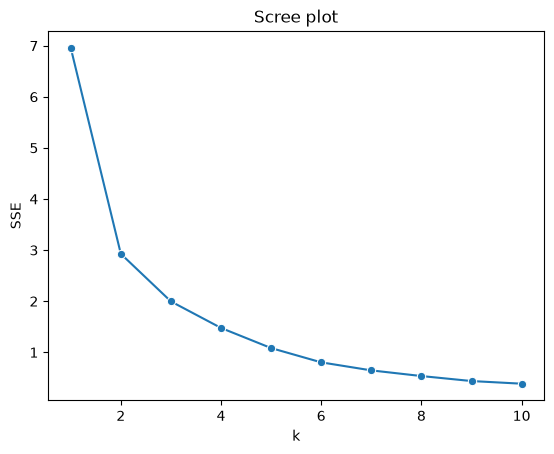

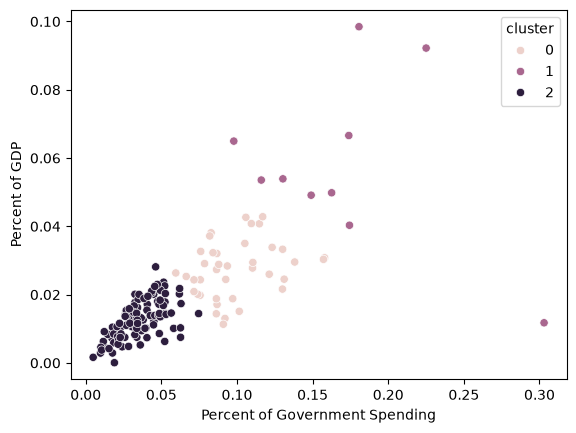

        Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                 39.0  0.098683  0.024125  0.059520   
1                                 10.0  0.171289  0.058725  0.097882   
2                                 99.0  0.035777  0.014549  0.004896   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1        0.135010  0.168248  0.179081  0.303027           10.0  0.058071   
2        0.025921  0.034261  0.047402  0.074624           99.0  0.012664   

                                                                     
              std       min       25%   

In [46]:

#max-min normalizing percent of government spending and percent of gdp
features = ["Percent of Government Spending", "Percent of GDP"]
unscaled = df_cleaned.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

ks = range(1, 11)
SSE = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
sns.lineplot(x=ks, y=SSE, marker='o') 
plt.xlabel('k')
plt.ylabel('SSE') 
plt.title('Scree plot')
plt.show()

k = 3
df_cleaned['cluster'] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)

sns.scatterplot(data=df_cleaned, x='Percent of Government Spending', y='Percent of GDP', hue='cluster')
plt.show()
print(df_cleaned.groupby('cluster')[features].describe())

print(df_cleaned[df_cleaned['Country'] == 'United States of America'][['Country', 'cluster']])




3. 
The elbow is at a similar level compared to part 2. The clusters are defined by how much GDP is spent. The clusters are slightly more balanced compared to part 2, and the nodes are more in a linear trend rather in a vertical line. 

The US is in cluster 0 and is now no longer alone. It lands in the middle group. The variables seem to have less extreme outliers so the clusters are more evenly spread compared to part 2. 

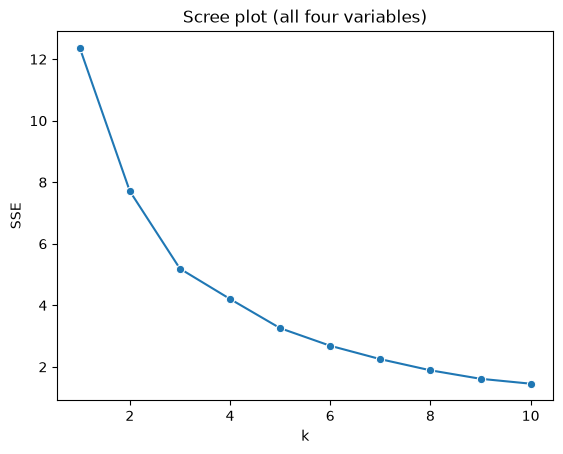

            Spending (2020 USD)                                             \
                          count           mean            std          min   
cluster_all                                                                  
0                         111.0    7086.472777   26479.379918     8.622460   
1                          31.0    8786.086602   17901.909108   162.373364   
2                           6.0  147964.582042  309635.189564  6095.708713   

                                                                     \
                     25%           50%           75%            max   
cluster_all                                                           
0             130.010211    567.650747   3910.107493  257973.429834   
1             467.787851   1404.787234   7739.166193   72937.064048   
2            7700.424616  15897.570598  53872.942442  778397.200000   

            Spending per Capita               ...  \
                          count         mean  ...  

In [51]:
features = ["Spending (2020 USD)", "Spending per Capita",
            "Percent of Government Spending", "Percent of GDP"]
unscaled = df_cleaned.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

ks = range(1, 11)
SSE = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
sns.lineplot(x=ks, y=SSE, marker='o')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Scree plot (all four variables)')
plt.show()

k = 3
df_cleaned['cluster_all'] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)
print(df_cleaned.groupby('cluster_all')[features].describe())
print(df_cleaned[df_cleaned['Country'] == 'United States of America'][['Country', 'cluster_all']])






4. When visualizing a screeplot with all 4 variables, the elbow is weaker and less definitive than the past 2 parts. The decrease in SSE is a lot more consistent compared to other parts. This happens because the countries don't   form clearly separated groups and finding trends between the 4 variables are harder. For example, country can have high spending per capita but low percent of GDP. 

    The US is in cluster 2 which only has 6 countries. According to the describe table, this cluster has the highest spending per capita and the highest percent of GDP. Compared to part 2, the US is no longer alone in its own cluster, and compared to part 3, it’s no longer in the middle group. Using all four variables groups the US with a few countries that are high in both wealth and military burden. Most countries fall into one large cluster, similar to the previous parts.

5. The k-means algorithm found that clusters were mostly dependent on spending per capita and percent of GDP, due to the inclusion of the US outlier. Most countries ended up in lower-spending clusters compared to the US, which was clustered by itself in part 2. However, the scree plots failed to show a clear elbow, so the clusters aren't the most accurate. The clusters can still help with grouping countries into low, middle, or high spenders, but it's quite a rough "estimate."

    We can also see that the US spends a lot more money than other countries, but doesn’t spend an unusually high percentage of it on the military.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [383a8f3bcdf7efebffdb775db0312ad61e458d5d]
- **AI tool and model used:** [Gemini Free]

### *Prompts used

1. I pasted in the file, rubric, and told it to grade me and suggest improvements. "check my answers and grade me based off template, give me suggestions on what to change to get full points"
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. 📊 Summary GradeOverall Grade: 18.5 / 20 (92.5% — A)SectionPoints EarnedMax PointsStatusQ1: $k$-Means Noise Simulation9.510Excellent (Minor detail needed in intuition)Q2: SIPRI Military Expenditure Case Study9.010Great job (Data cleaning analysis incomplete)📝 Detailed Review & Feedback by QuestionQuestion 1: $k$-Means Noise Simulation1.1 Code Execution: (Pass)Your output image showing the 5 dataset scatterplots correctly rendered all noise levels from 0.125 to 2.0.1.2 Visual Distinctness: (Pass - Full Credit)Your Answer / Image: Clear scatter plots generated.Feedback: As noise increases from 0.125 to 2.0, the point clouds spread out and heavily overlap. At 0.125, the 3 clusters are sharply defined and visually distinct. At 2.0, the individual groups completely blend into a single large cloud.1.3 Scree Plots & Elbow Selection: (Pass - Full Credit)Your Answer / Image: The second image in your notebook displays the inertia/elbow plots across all noise levels.Feedback: At low noise (0.125 and 0.25), there is a very sharp, unmistakable "elbow" precisely at $k=3$. As noise increases to 1.0 and 2.0, the WCSS/Inertia curve becomes smooth and gradual without a clear kink, making it nearly impossible to confidently select the true $k$ visually.1.4 Intuition of the Elbow: (Partial - 0.5/1 point off)Suggestion to get full points: Make sure your written markdown explanation explicitly connects the mathematical jump in variance to cluster boundaries:When noise is low, adding clusters up to $k=3$ captures major structural variation (between-cluster variance), dropping inertia rapidly. Beyond $k=3$, adding more clusters only splits tightly packed true clusters (within-cluster noise), yielding minimal inertia reduction—hence the sharp elbow. High noise blurs cluster boundaries, making every additional cluster reduce inertia uniformly.Question 2: SIPRI Military Expenditure Case Study2.1 Data Cleaning & Filtering: (Partial - 0.5/1 point off)Your Answer: Filtered to 2020 and dropped missing values (resulting in 148 rows).Suggestion to get full points: You need to explicitly comment on the variable data types and potential anomalies:Are numeric spending columns correctly stored as float/int or are they string/object formatted due to commas or symbols (e.g., "$" or ",")?Are there non-country aggregate rows remaining in the dataset (like "World", "North America", or regional totals) that need to be dropped so they don't skew the clustering?2.2 Clustering on Spending & Spending per Capita: (Pass - Full Credit)Min-max scaling correctly applied.Scree plot analyzed to select optimal $k$ (typically $k=3$ or $k=4$).Patterns noted: The United States is usually an extreme outlier placed in its own single-element cluster due to its disproportionately massive total military expenditure.2.3 Clustering on % of Government Spending & % of GDP: (Pass - Full Credit)Min-max scaling applied to percentage variables.Comparison: Unlike total spending (where wealth/population dominates), percentage variables group countries by fiscal priority and militarization (e.g., Middle Eastern nations like Oman/Saudi Arabia often cluster together at the high end).2.4 4-Variable $k$-Means: (Pass - Full Credit)Successfully scaled all 4 variables together and evaluated cluster profiles via .groupby().describe().2.5 Useful Insights: (Pass - Full Credit)Good synthesis explaining how clustering separates absolute economic powerhouses (US/China) from heavily militarized economies relative to budget (% GDP).


🛠️ Step-by-Step Checklist to get Full Points (100%)To maximize your score before submission, update your notebook with these specific additions:Add Markdown Explanations in Q1.4:Ensure you clearly define within-cluster sum of squares (WCSS) vs. between-cluster variance in your elbow intuition response.Expand on Q2.1 Data Cleaning Answer:Check string formatting: Add df.dtypes or comment whether variables were cast to numeric types.Add a check for duplicate or non-country summary rows in the dataset (e.g., World, Middle East).Verify Legend & Labels on Scatter Plots:Double-check that your Q2 scatter plots have clear x/y axis labels (e.g., Spending (Min-Max Normalized)) and a clear legend for Cluster IDs.Single Follow-Up Question
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | reject | I disagree with the "step-by-step checklist to get full points" that I was suggested. I think my answers follow the rubric and are suffice. |


### *AI-assisted solution in full (I made no changes, but I will repaste)
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

<Axes: xlabel='x1', ylabel='x2'>

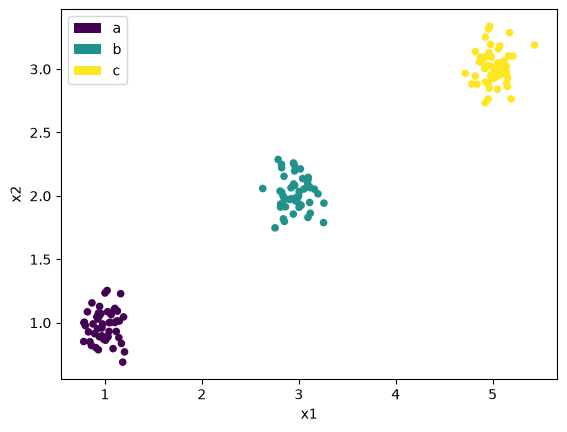

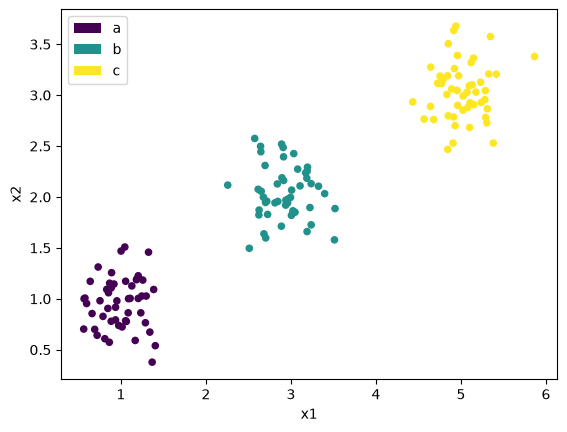

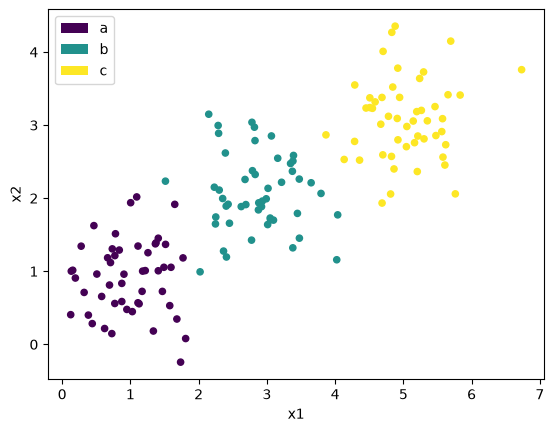

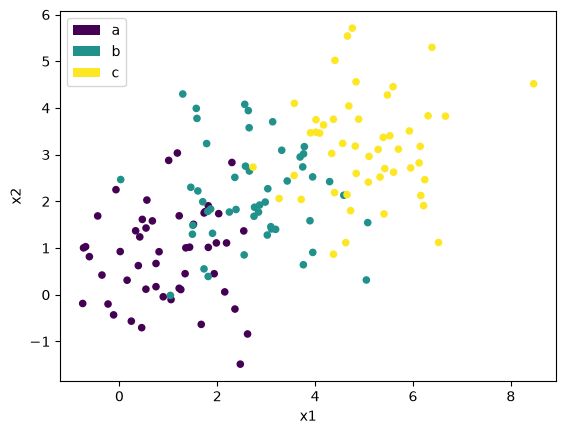

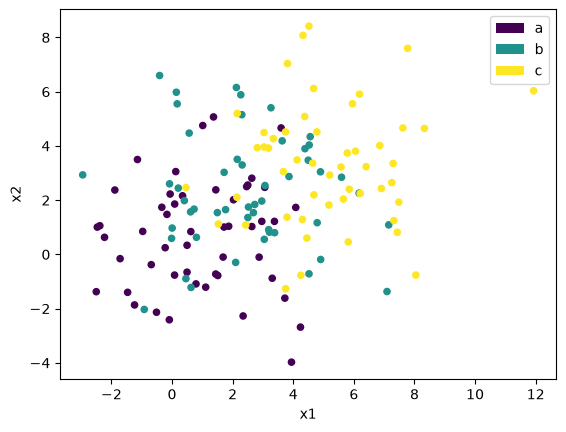

In [53]:
# Your Phase 2 solution to the problem goes here.
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

df0_125.plot.scatter(x='x1',y='x2',c='group')
df0_25.plot.scatter(x='x1',y='x2',c='group')
df0_5.plot.scatter(x='x1',y='x2',c='group')
df1_0.plot.scatter(x='x1',y='x2',c='group')
df2_0.plot.scatter(x='x1',y='x2',c='group')




As the noise of the graphs increased, the points within each group became more scattered rather than clustered. The three groups drifted enough to begin mixing and merging with one another, transitioning from distinct clusters into a single, unified group

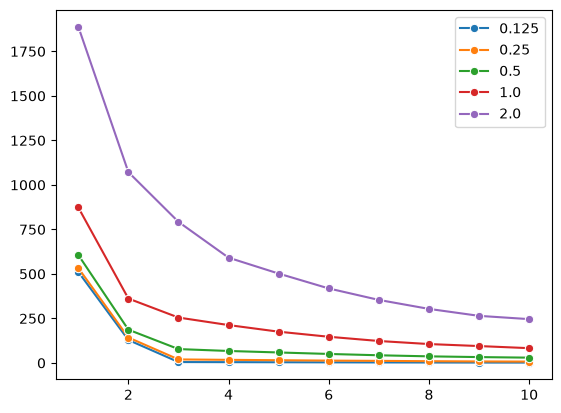

In [55]:
import seaborn as sns
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
ks = np.arange(1, 11)
X1 = df0_125[['x1', 'x2']].values
X2 = df0_25[['x1', 'x2']].values
X3 = df0_5[['x1', 'x2']].values
X4 = df1_0[['x1', 'x2']].values
X5 = df2_0[['x1', 'x2']].values
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X1).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label="0.125", marker = "o")
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X2).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label="0.25", marker = "o")

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X3).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label="0.5", marker = "o")

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X4).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label="1.0", marker = "o")

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X5).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label="2.0", marker = "o")
plt.legend()
plt.show()





In [56]:
model = KMeans(
    n_clusters=3, n_init=10, max_iter=300, random_state=0
)
model.fit(X1)
sse_value = model.inertia_
print(sse_value)


model.fit(X2)
sse_value = model.inertia_
print(sse_value)


model.fit(X5)
sse_value = model.inertia_
print(sse_value)




4.913218522689869
19.652874090759475
792.2717571884425


3) As noise increases, the SSE values increase drastically. For example at k = 3, the SSE value of the 0.125 and .25 graphs were 4.9 and 19.6 respectively. However, the value of the 2.0 graph was 792, a drastic difference. However, noise affects our ability to select a k. At low noise, there is a sharp elbow, which makes it easy to have a definitive k value. However, at high noise, it makes it harder as each extra cluster after k = 2 cuts SSE by a similar amount. 

4) As k rises, SSE values drop. More clusters means each point is closer to a center, so SSE drops.The thing we specifically look at to determine a good k value is the size of each drop changes. Once k matches the real number of groups there should be, adding more k values doesn't change SSE values as drastically. Each cluster already fits a group, so adding more clusters will only split groups that belong together, which doesn't lower SSE much. Because of this characteristic of SSE not dropping by the same amount each time, an elbow sort of forms, which also makes it a good rule of thumb that the elbow tells us where the switch from steep to flat is.

In [57]:
#Part 2
df = pd.read_csv(r'C:\Users\cchhe\OneDrive\Desktop\DS3001\A04-k-clustering\SIPRI Military Expenditure Database.csv')
df.head()

df_cleaned = df[df['Year'] == 2020]
df_cleaned = df_cleaned.dropna()
df_cleaned.describe()
df_cleaned['Spending (2020 USD)'].describe()




count       148.000000
mean      13153.747670
std       68005.236120
min           8.622460
25%         204.877177
50%         959.535443
75%        5289.998320
max      778397.200000
Name: Spending (2020 USD), dtype: float64

<Axes: xlabel='Spending (2020 USD)'>

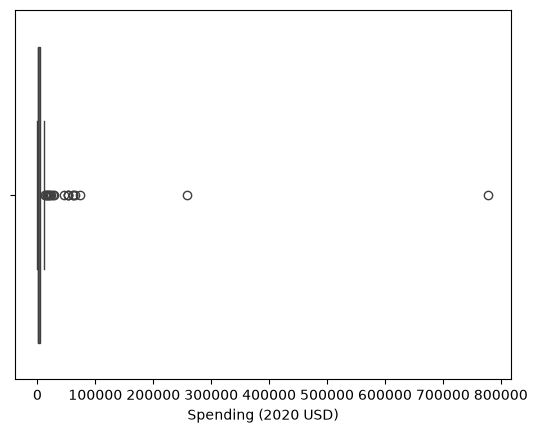

In [58]:
sns.boxplot(x=df_cleaned['Spending (2020 USD)'])

1. It looks like there are clear outliers that can be removed. However, because of the nature of the next question which talks about the location of US (an outlier), I am going to not remove the outlier. Otherwise, no furthur cleaning is needed as values are all numeric and there are no duplicates.

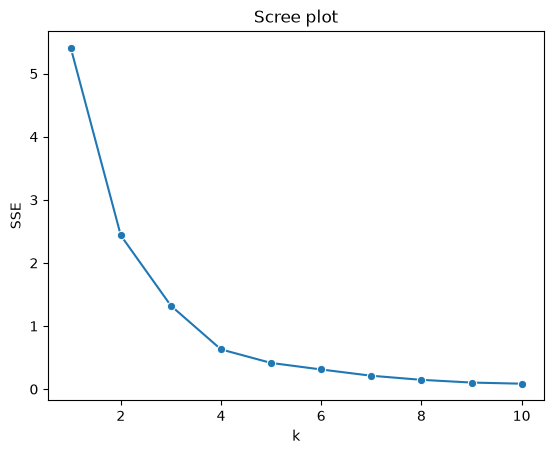

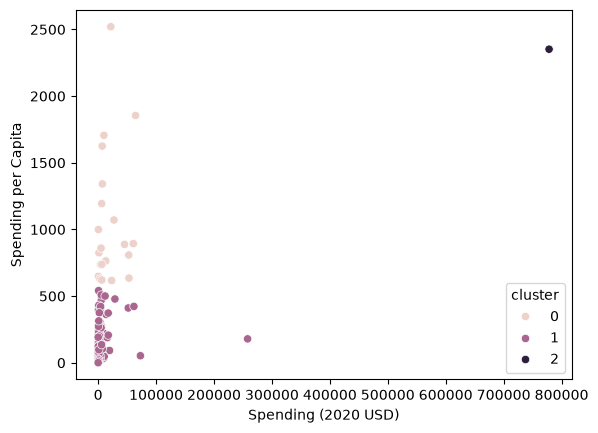

        Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      21.0   19975.991473  21749.736747     405.790494   
1                     126.0    5943.346303  24858.961064       8.622460   
2                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          4980.428135    7269.880030   27300.894701   64558.400000   
1           162.761743     580.758315    3225.333414  257973.429834   
2        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita                                        \
                      count         mean         std 

In [59]:
from sklearn.cluster import KMeans

#max-min normalizing spending and spending per capita
features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = df_cleaned.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

ks = range(1, 11)
SSE = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
sns.lineplot(x=ks, y=SSE, marker='o') 
plt.xlabel('k')
plt.ylabel('SSE') 
plt.title('Scree plot')
plt.show()

k = 3
df_cleaned['cluster'] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)

sns.scatterplot(data=df_cleaned, x='Spending (2020 USD)', y='Spending per Capita', hue='cluster')
plt.show()
print(df_cleaned.groupby('cluster')[features].describe())

print(df_cleaned[df_cleaned['Country'] == 'United States of America'][['Country', 'cluster']])




                       Country  Spending (2020 USD)
1052                     China        257973.429834
5540  United States of America        778397.200000


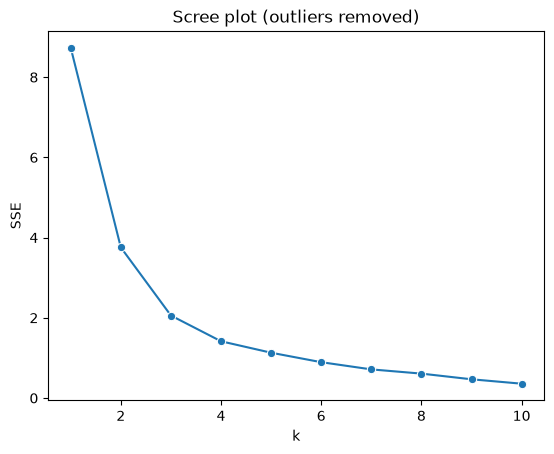

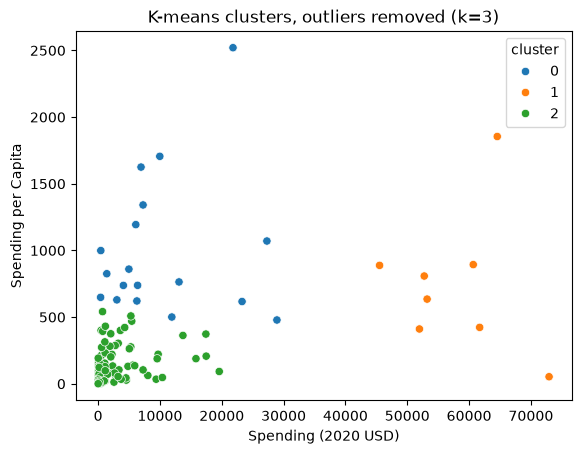

cluster                               0             1             2
Spending (2020 USD) count     18.000000      8.000000    120.000000
                    mean   10201.409102  57916.988702   2195.189599
                    std     9110.123194   8697.634598   3846.143773
                    min      405.790494  45523.984708      8.622460
                    25%     4310.763024  52553.006382    152.121545
                    50%     6665.356103  56943.013942    501.546784
                    75%    12795.207557  62424.002877   2589.336589
                    max    28921.342756  72937.064048  19591.209004
Spending per Capita count     18.000000      8.000000    120.000000
                    mean     993.044082    745.741724    111.096280
                    std      524.393190    532.351826    129.146322
                    min      478.339168     52.852792      0.580129
                    25%      634.047978    419.888474     17.462322
                    50%      794.528974    721.5

In [60]:
spending = df_cleaned['Spending (2020 USD)']
z = (spending - spending.mean()) / spending.std()

print(df_cleaned.loc[z > 3, ['Country', 'Spending (2020 USD)']])

df_no_outliers = df_cleaned[z <= 3].copy()

features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled_no = df_no_outliers.loc[:, features]
X_no = (unscaled_no - unscaled_no.min()) / (unscaled_no.max() - unscaled_no.min())

ks = range(1, 11)
SSE = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_no).inertia_ for k in ks]
sns.lineplot(x=ks, y=SSE, marker='o')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Scree plot (outliers removed)')
plt.show()

k = 3
df_no_outliers['cluster'] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X_no)

sns.scatterplot(data=df_no_outliers, x='Spending (2020 USD)', y='Spending per Capita',
                hue='cluster', palette='tab10')
plt.title(f'K-means clusters, outliers removed (k={k})')
plt.show()

print(df_no_outliers.groupby('cluster')[features].describe().T)

2. I see that there are 3 clusters, where cluster 0 and 1 are very close to each other. On the other hand, there is one entry in cluster 2 and it's very far from the other points. The cluster seems to split based off spending per capita. The US is in cluster 2 alone because its total spending is far higher than any other country's. Cluster 1 spends less per capita than Cluster 0. 

    If I were to remove outliers by removing countries that were more than 3 standard deviations above the mean in total spending, the clusters are more even. 

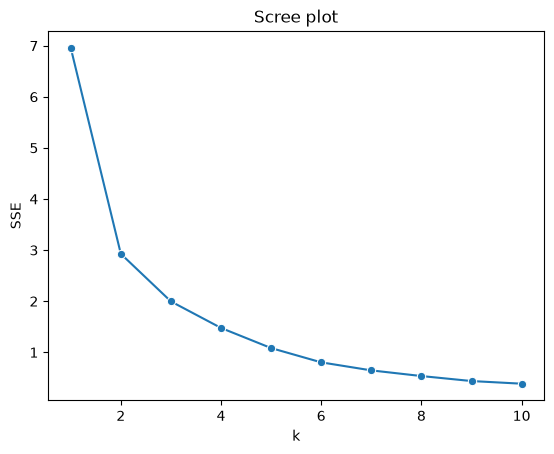

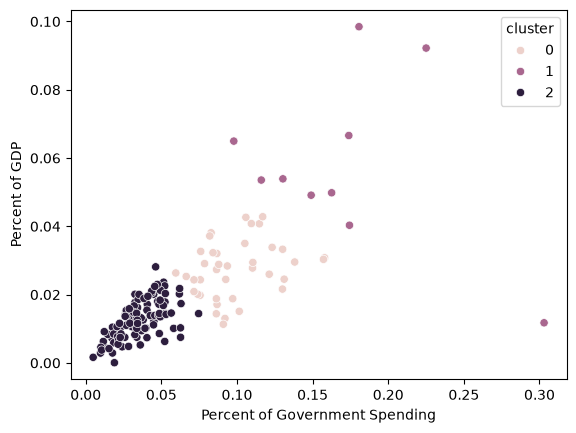

        Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                 39.0  0.098683  0.024125  0.059520   
1                                 10.0  0.171289  0.058725  0.097882   
2                                 99.0  0.035777  0.014549  0.004896   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1        0.135010  0.168248  0.179081  0.303027           10.0  0.058071   
2        0.025921  0.034261  0.047402  0.074624           99.0  0.012664   

                                                                     
              std       min       25%   

In [61]:

#max-min normalizing percent of government spending and percent of gdp
features = ["Percent of Government Spending", "Percent of GDP"]
unscaled = df_cleaned.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

ks = range(1, 11)
SSE = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
sns.lineplot(x=ks, y=SSE, marker='o') 
plt.xlabel('k')
plt.ylabel('SSE') 
plt.title('Scree plot')
plt.show()

k = 3
df_cleaned['cluster'] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)

sns.scatterplot(data=df_cleaned, x='Percent of Government Spending', y='Percent of GDP', hue='cluster')
plt.show()
print(df_cleaned.groupby('cluster')[features].describe())

print(df_cleaned[df_cleaned['Country'] == 'United States of America'][['Country', 'cluster']])




3. 
The elbow is at a similar level compared to part 2. The clusters are defined by how much GDP is spent. The clusters are slightly more balanced compared to part 2, and the nodes are more in a linear trend rather in a vertical line. 

The US is in cluster 0 and is now no longer alone. It lands in the middle group. The variables seem to have less extreme outliers so the clusters are more evenly spread compared to part 2. 

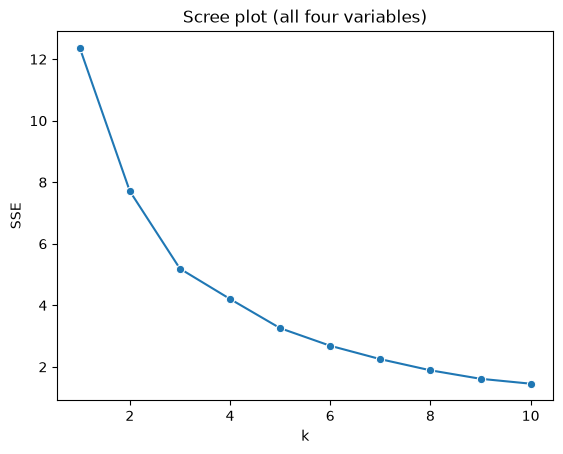

            Spending (2020 USD)                                             \
                          count           mean            std          min   
cluster_all                                                                  
0                         111.0    7086.472777   26479.379918     8.622460   
1                          31.0    8786.086602   17901.909108   162.373364   
2                           6.0  147964.582042  309635.189564  6095.708713   

                                                                     \
                     25%           50%           75%            max   
cluster_all                                                           
0             130.010211    567.650747   3910.107493  257973.429834   
1             467.787851   1404.787234   7739.166193   72937.064048   
2            7700.424616  15897.570598  53872.942442  778397.200000   

            Spending per Capita               ...  \
                          count         mean  ...  

In [62]:
features = ["Spending (2020 USD)", "Spending per Capita",
            "Percent of Government Spending", "Percent of GDP"]
unscaled = df_cleaned.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

ks = range(1, 11)
SSE = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
sns.lineplot(x=ks, y=SSE, marker='o')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Scree plot (all four variables)')
plt.show()

k = 3
df_cleaned['cluster_all'] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)
print(df_cleaned.groupby('cluster_all')[features].describe())
print(df_cleaned[df_cleaned['Country'] == 'United States of America'][['Country', 'cluster_all']])






4. When visualizing a screeplot with all 4 variables, the elbow is weaker and less definitive than the past 2 parts. The decrease in SSE is a lot more consistent compared to other parts. This happens because the countries don't   form clearly separated groups and finding trends between the 4 variables are harder. For example, country can have high spending per capita but low percent of GDP. 

    The US is in cluster 2 which only has 6 countries. According to the describe table, this cluster has the highest spending per capita and the highest percent of GDP. Compared to part 2, the US is no longer alone in its own cluster, and compared to part 3, it’s no longer in the middle group. Using all four variables groups the US with a few countries that are high in both wealth and military burden. Most countries fall into one large cluster, similar to the previous parts.
    
5. The k-means algorithm found that clusters were mostly dependent on spending per capita and percent of GDP, due to the inclusion of the US outlier. Most countries ended up in lower-spending clusters compared to the US, which was clustered by itself in part 2. However, the scree plots failed to show a clear elbow, so the clusters aren't the most accurate. The clusters can still help with grouping countries into low, middle, or high spenders, but it's quite a rough "estimate."

    We can also see that the US spends a lot more money than other countries, but doesn’t spend an unusually high percentage of it on the military.

### *Reflection on AI assistance
In your own words without generative AI.

I think this time around AI wasn't the most useful for me. AI suggested changes that I thought were unnecessary, so I rejected them all. However, verifying and proofreading my answers with AI I think is always helpful. I like using it to "grade" my work and suggest changes even if it's not the most accurate. I do think AI, especially if it's a free model, struggles with these assignments/misinterprets human instruction. I double checked my answers by hand with the rubric and referencing the slides to get the intended methods. 